<a href="https://colab.research.google.com/github/shilnagovindan2011/test/blob/main/FINAL_PROJECT_breast_cancer_Wisconsin_(Diagnostic)_dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## AGENTIC AI-POWERED DIGITAL TWIN FOR PERSONALIZED CANCER DIAGNOSIS AND TREATMENT OUTCOME PREDICTION

# project work flow-dataset 1

Breast Cancer Dataset
        ↓
Load Dataset
        ↓
Understand Dataset
        ↓
Check Missing Values
        ↓
Exploratory Data Analysis
        ↓
Separate Features and Target
        ↓
Encode B/M → 0/1
        ↓
Train-Test Split
        ↓
Feature Scaling
        ↓
Train ML Models
   ┌────────┬───────────┐
   ↓        ↓           ↓
Logistic   Random     XGBoost
Regression Forest
   └────────┴───────────┘
             ↓
       Model Evaluation
             ↓
 Confusion Matrix / Accuracy /
 Precision / Recall / F1 / AUC
             ↓
       Feature Importance
             ↓
          SHAP
             ↓
   Diagnosis Prediction Agent
             ↓
      Dataset 2 – Survival

In [ ]:
# 1. Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)
#These libraries provide the tools required for data preprocessing, visualization, machine-learning model development, and evaluation.

In [ ]:

# 2. Load Dataset
# The dataset is successfully loaded and contains patient IDs, diagnosis labels, and numerical characteristics of cell nuclei obtained from breast-mass images.

df = pd.read_csv("/content/breast_cancer_data.csv")
df

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,927241,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


In [ ]:
print(df.head())

         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980              0.10430   

   ...  radius_worst  texture_worst  perimeter_worst  area_wor

In [ ]:
# Find Dataset Shape
# 3. Dataset Shape

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 569
Number of columns: 32


In [ ]:
df.columns # list the all column names

Index(['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean',
       'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean',
       'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean',
       'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se',
       'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se',
       'fractal_dimension_se', 'radius_worst', 'texture_worst',
       'perimeter_worst', 'area_worst', 'smoothness_worst',
       'compactness_worst', 'concavity_worst', 'concave points_worst',
       'symmetry_worst', 'fractal_dimension_worst'],
      dtype='object')

In [ ]:
# Dataset Information
# to show the Number of rows
#Number of columns
#Data type
#Missing values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

In [ ]:
# Statistical Summary
df.describe()

,id,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


In [ ]:
df.isnull().sum()  #isnull()Finds missing values and sum() means Counts missing values

,0
id,0
diagnosis,0
radius_mean,0
texture_mean,0
perimeter_mean,0
area_mean,0
smoothness_mean,0
compactness_mean,0
concavity_mean,0
concave points_mean,0


there is No missing values

In [ ]:
df['diagnosis'].value_counts()  # B- 357(benign), # M- 212(Malignant)


# 8. to Check Diagnosis Distribution,because diagnosis is our target.
print(df['diagnosis'].value_counts())
print(df['diagnosis'].value_counts(normalize=True) * 100)

diagnosis
B    357
M    212
Name: count, dtype: int64
diagnosis
B    62.741652
M    37.258348
Name: proportion, dtype: float64


In [ ]:
# CHECK DATA TYPES
# 5. Data Types
print(df.dtypes)

id                           int64
diagnosis                   object
radius_mean                float64
texture_mean               float64
perimeter_mean             float64
area_mean                  float64
smoothness_mean            float64
compactness_mean           float64
concavity_mean             float64
concave points_mean        float64
symmetry_mean              float64
fractal_dimension_mean     float64
radius_se                  float64
texture_se                 float64
perimeter_se               float64
area_se                    float64
smoothness_se              float64
compactness_se             float64
concavity_se               float64
concave points_se          float64
symmetry_se                float64
fractal_dimension_se       float64
radius_worst               float64
texture_worst              float64
perimeter_worst            float64
area_worst                 float64
smoothness_worst           float64
compactness_worst          float64
concavity_worst     

In [ ]:
# Check Duplicate Records and duplicate ID
print("Duplicate rows:", df.duplicated().sum())
print("Unique IDs:", df['id'].nunique())

Duplicate rows: 0
Unique IDs: 569


There are 569 records and 569 unique IDs, Each record has a unique patient identifier, and duplicate records are not present.

# **Visualization**

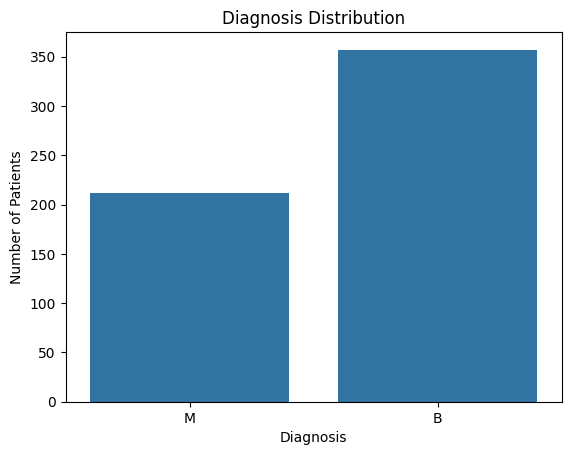

In [ ]:
sns.countplot(x='diagnosis', data=df)

plt.title("Diagnosis Distribution")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Patients")

plt.show()

In [ ]:
from imblearn.over_sampling import SMOTE
from collections import Counter

# Drop irrelevant columns ('id' and 'Unnamed: 32') that contain NaNs
df_processed = df.drop(['id', 'Unnamed: 32'], axis=1, errors='ignore')

# Features and target
X = df_processed.drop('diagnosis', axis=1)
y = df_processed['diagnosis']

print("Before Balancing:", Counter(y))

# Apply SMOTE
smote = SMOTE(random_state=42)
X_balanced, y_balanced = smote.fit_resample(X, y)

print("After Balancing:", Counter(y_balanced))

Before Balancing: Counter({'B': 357, 'M': 212})
After Balancing: Counter({'M': 357, 'B': 357})


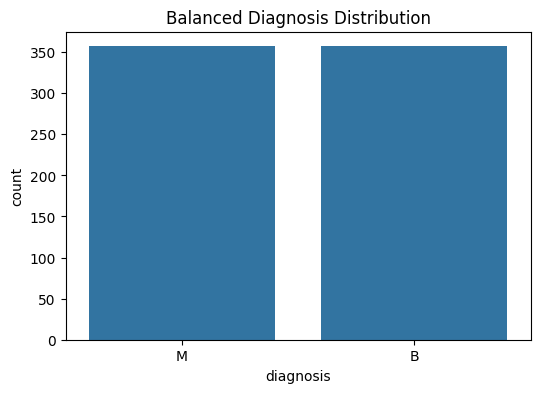

In [ ]:
balanced_df = pd.DataFrame(X_balanced, columns=X.columns)
balanced_df['diagnosis'] = y_balanced

plt.figure(figsize=(6,4))
sns.countplot(x='diagnosis', data=balanced_df)
plt.title('Balanced Diagnosis Distribution')
plt.show()

## Scale the Data

Now i used to scale the data for Logistic Regression, It is better to perform scaling before SMOTE. when using SMOTE, because SMOTE uses distances between observations.

In [ ]:
# 1. Split RAW data first
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 2. Scale using ONLY training data statistics
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)   # test set never influences the scaler

# 3. Balance ONLY the training set
smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train_scaled, y_train)

# Now train each model on X_train_balanced/y_train_balanced,
# and evaluate on the untouched X_test_scaled / y_test

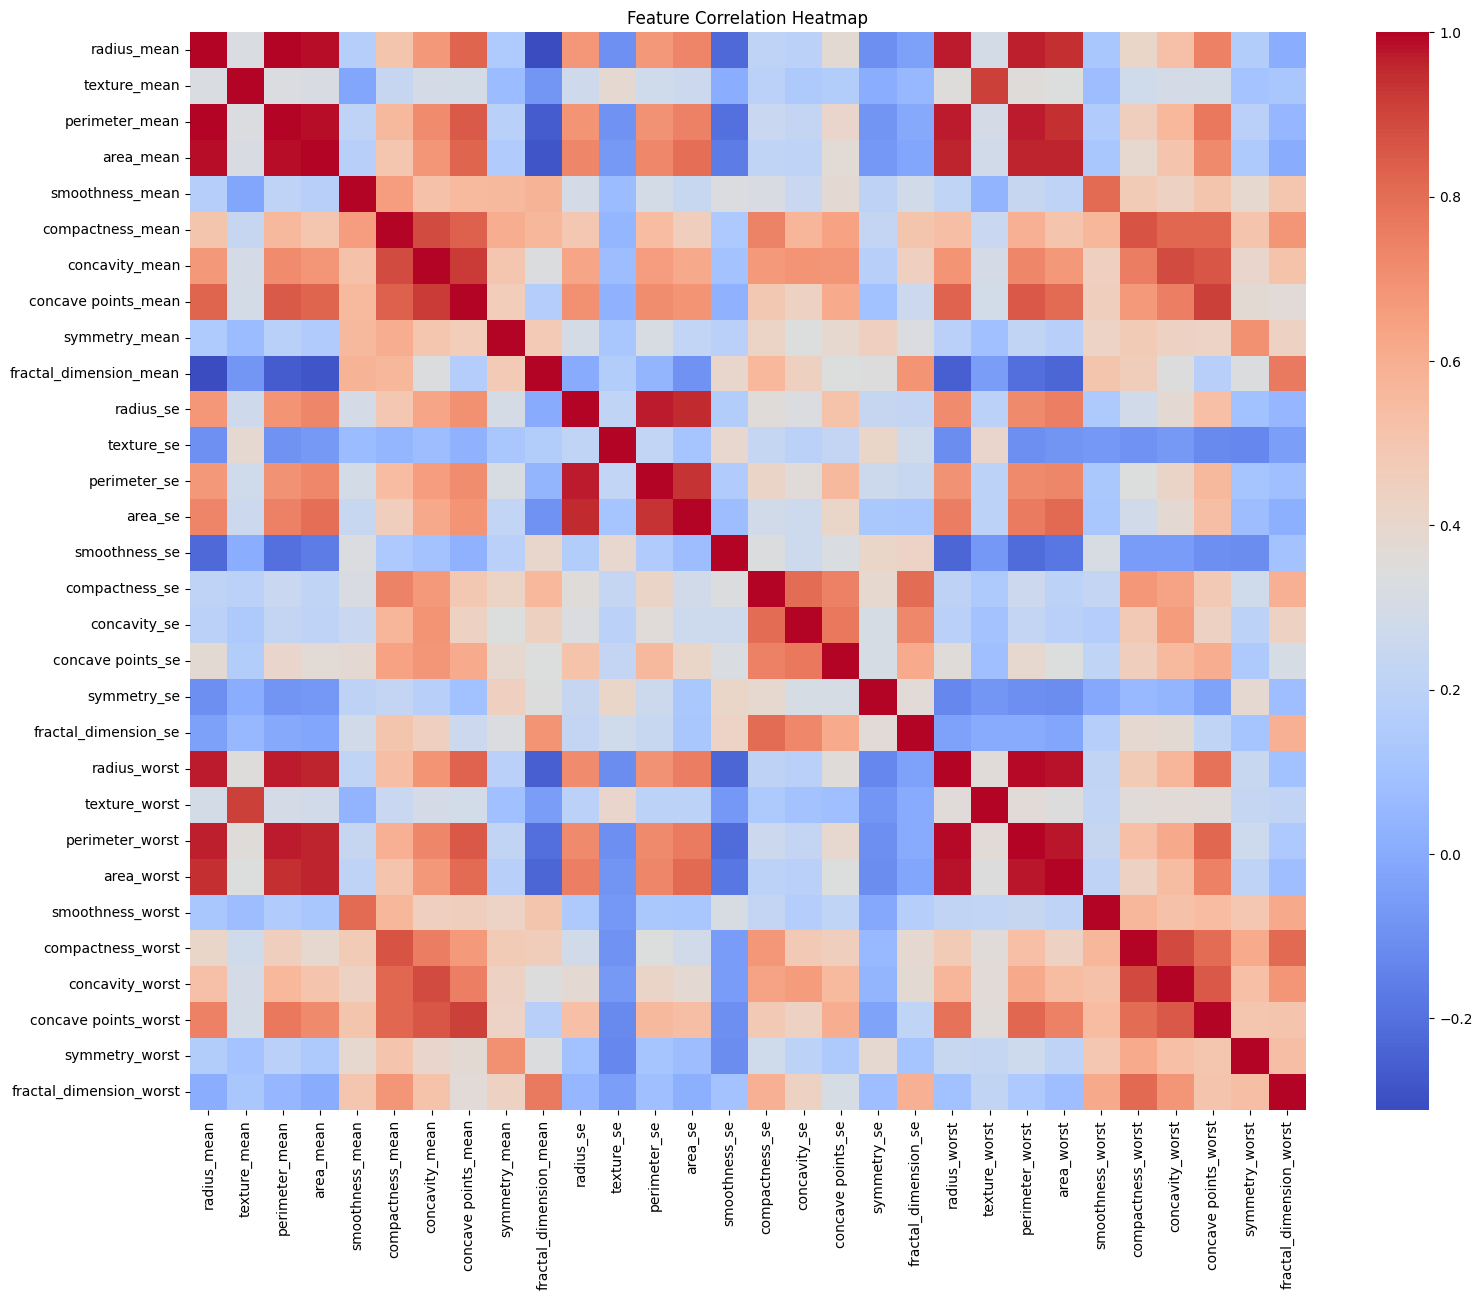

In [ ]:
# ===== EXPLORATORY DATA ANALYSIS (EDA) =====

# 1. Correlation heatmap — shows which features move together
plt.figure(figsize=(18, 14))
corr_matrix = df.drop(columns=['id']).corr(numeric_only=True)
sns.heatmap(corr_matrix, cmap='coolwarm', annot=False)
plt.title("Feature Correlation Heatmap")
plt.show()
# Why: many of the 30 features are redundant (e.g. radius/perimeter/area are
# all measuring "size"), which helps explain later feature-importance results.



In [ ]:
# 2. Correlation of each feature with the target
df_corr = df.drop(columns=['id']).copy()
df_corr['diagnosis'] = df_corr['diagnosis'].map({'B': 0, 'M': 1})
target_corr = df_corr.corr()['diagnosis'].sort_values(ascending=False)
print("Features most correlated with diagnosis:\n", target_corr.head(11))
# Why: quick numeric preview of which raw features are likely to matter —
# should roughly agree with the SHAP/feature-importance results later.

Features most correlated with diagnosis:
 diagnosis               1.000000
concave points_worst    0.793566
perimeter_worst         0.782914
concave points_mean     0.776614
radius_worst            0.776454
perimeter_mean          0.742636
area_worst              0.733825
radius_mean             0.730029
area_mean               0.708984
concavity_mean          0.696360
concavity_worst         0.659610
Name: diagnosis, dtype: float64


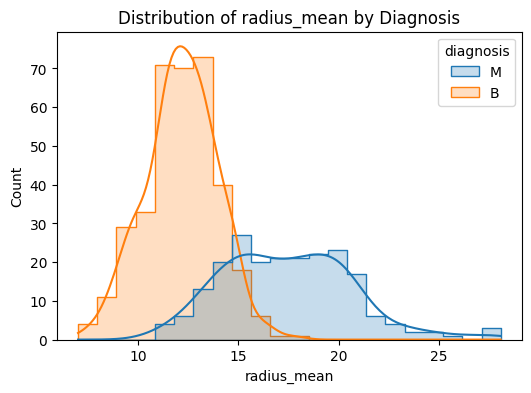

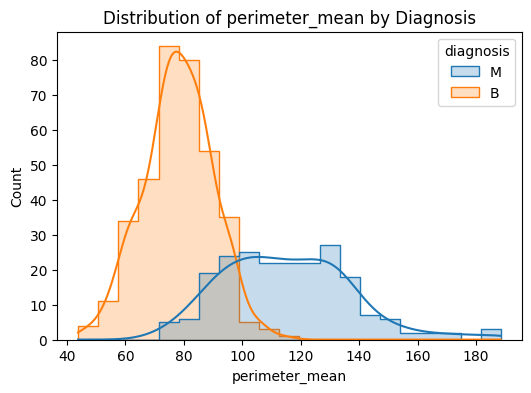

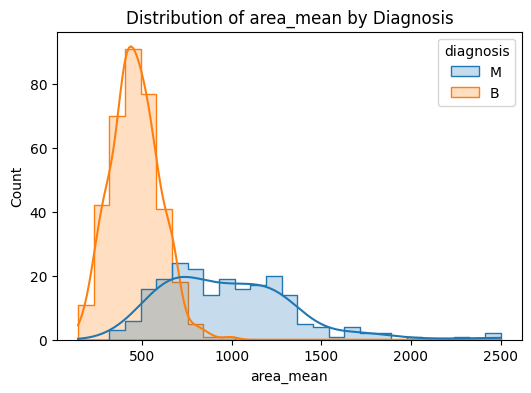

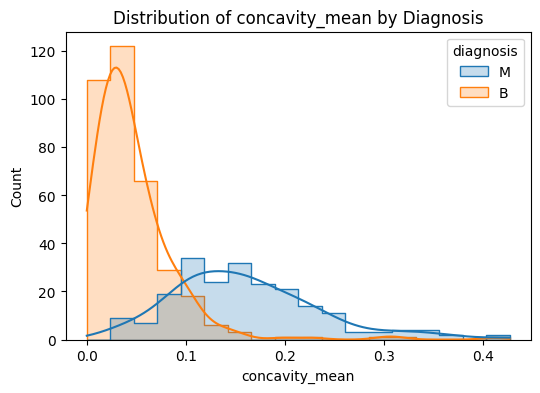

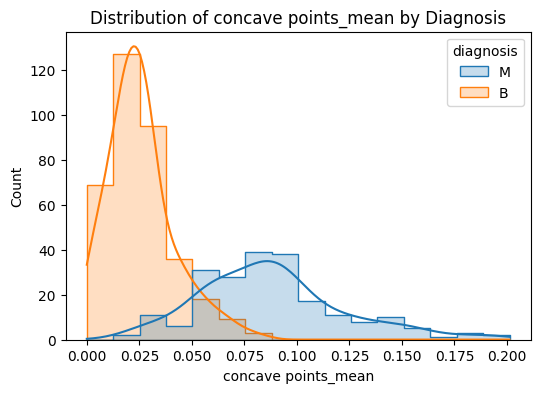

In [ ]:
# 3. Distribution of key features, split by diagnosis
key_features = ['radius_mean', 'perimeter_mean', 'area_mean',
                 'concavity_mean', 'concave points_mean']
for feature in key_features:
    plt.figure(figsize=(6, 4))
    sns.histplot(data=df, x=feature, hue='diagnosis', kde=True, element='step')
    plt.title(f"Distribution of {feature} by Diagnosis")
    plt.show()
# Why: shows how separable malignant vs benign cases are on each feature —
# a big separation between the two hue curves = a strong predictor.



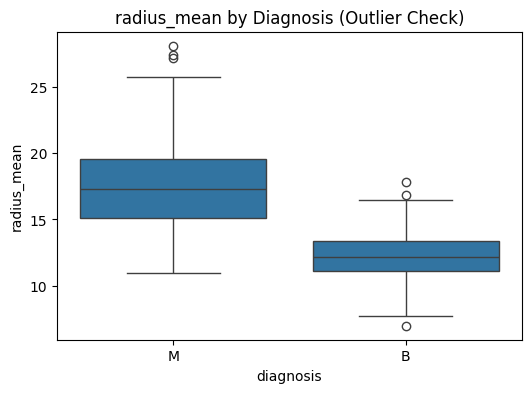

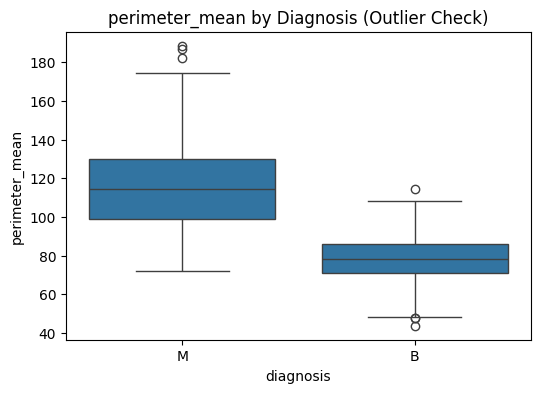

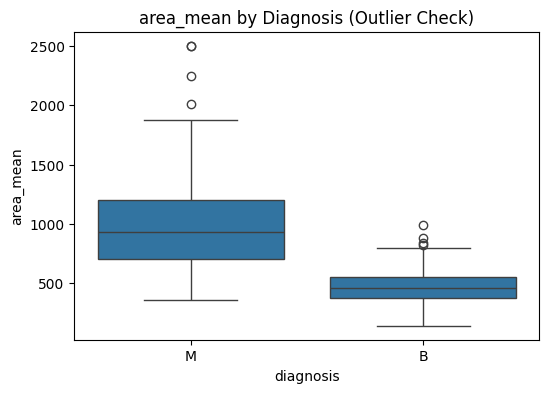

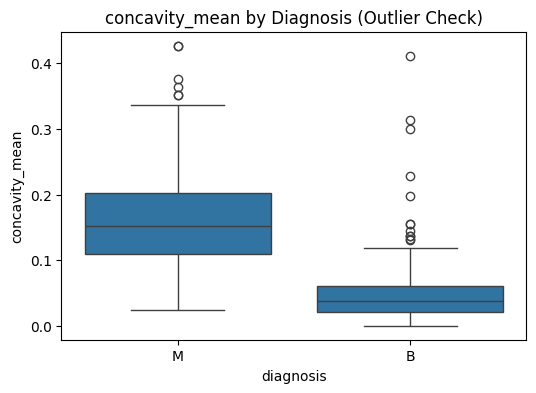

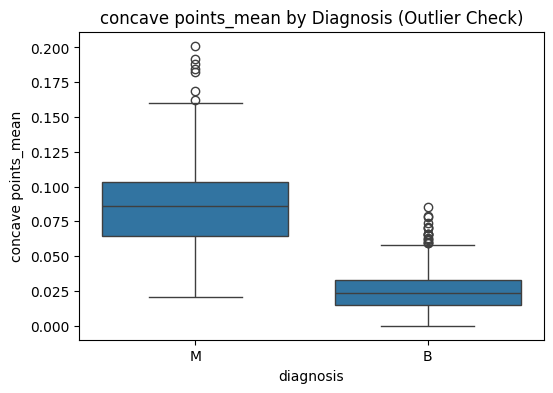

In [ ]:
# 4. Boxplots — outlier detection
for feature in key_features:
    plt.figure(figsize=(6, 4))
    sns.boxplot(data=df, x='diagnosis', y=feature)
    plt.title(f"{feature} by Diagnosis (Outlier Check)")
    plt.show()
# Why: malignant tumors tend to have wider spread/more outliers on size
# features — good to flag before modeling, since tree models are robust to
# outliers but Logistic Regression is more sensitive to them.



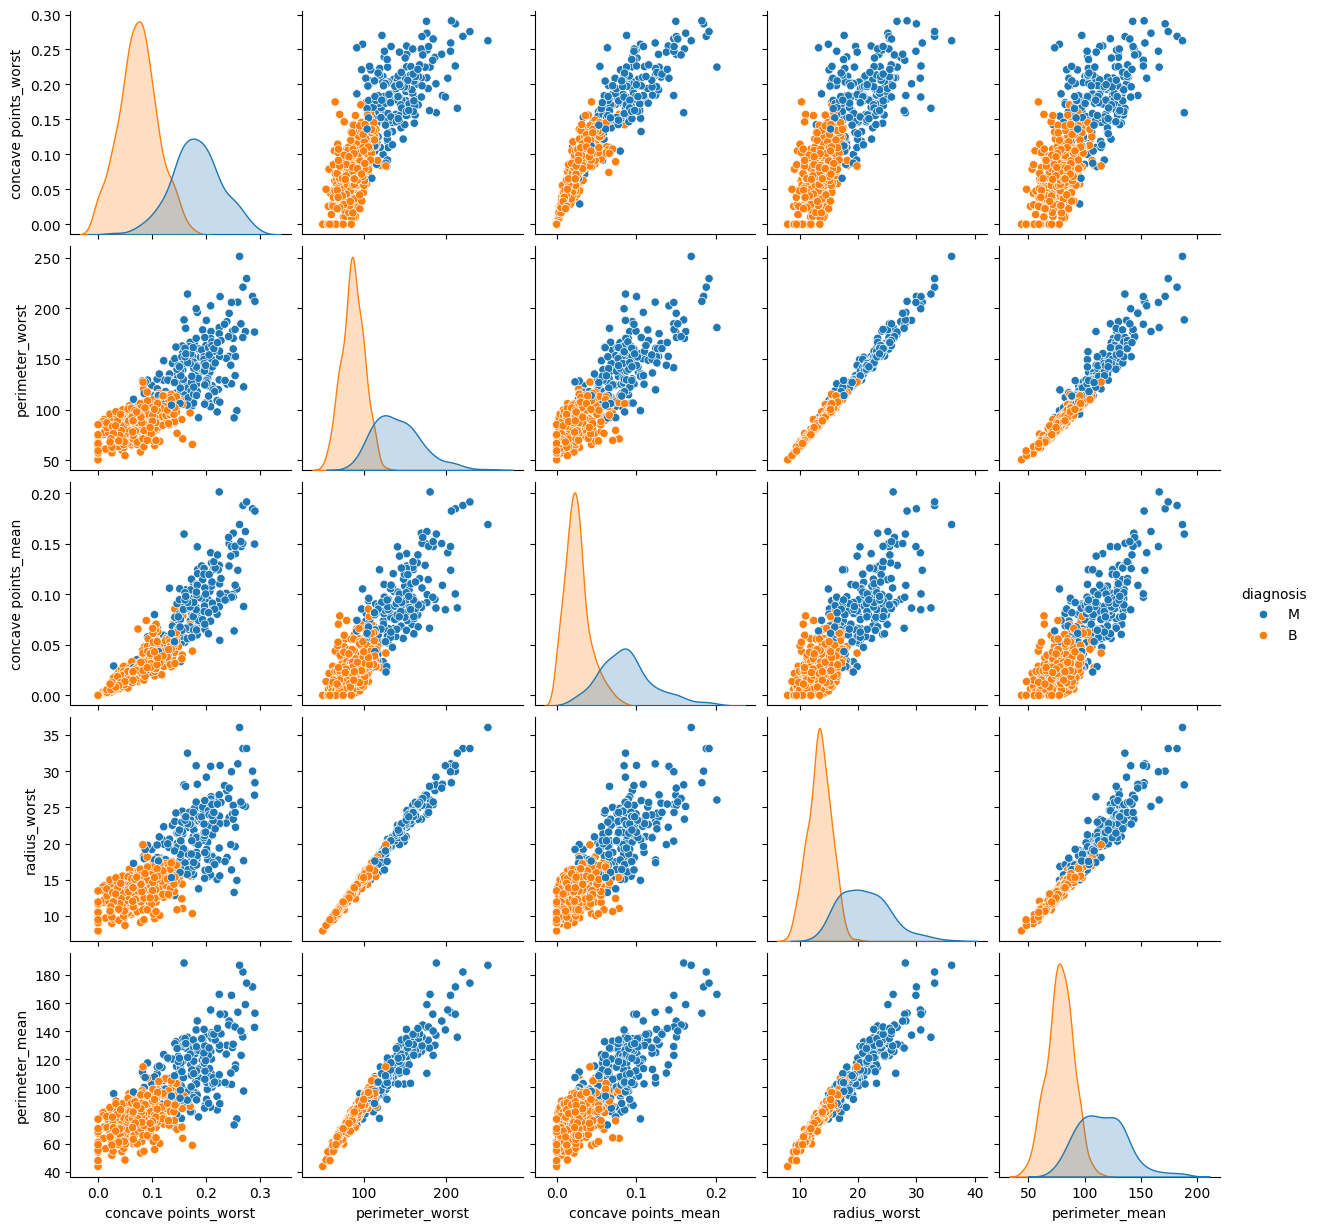

In [ ]:
# 5. Pairplot of the top correlated features
top_features = target_corr.index[1:6].tolist()  # top 5, excluding diagnosis itself
sns.pairplot(df, vars=top_features, hue='diagnosis', diag_kind='kde')
plt.show()
# Why: visualizes how well combinations of the strongest features separate
# the two classes — a good sanity check before you even train a model.

In [ ]:
The data has already been split, scaled, and the training set balanced in the `Split, Scale, and Balance Training Data` section (e.g., cell `Njdo3bQqEis1`). The variables `X_train_balanced`, `y_train_balanced`, `X_test_scaled`, and `y_test` are ready for model training and evaluation.

In [ ]:
The SMOTE balancing has already been applied to the scaled training data in the `Split, Scale, and Balance Training Data` section (e.g., cell `Njdo3bQqEis1`). The `X_train_balanced` and `y_train_balanced` variables are now ready to be used for training all models.

Before SMOTE:
diagnosis
B    288
M    283
Name: count, dtype: int64

After SMOTE:
diagnosis
M    288
B    288
Name: count, dtype: int64


In [ ]:
# Train Logistic Regression Using Balanced Data


# 16. Logistic Regression

lr = LogisticRegression(
    max_iter=5000,
    random_state=42
)

lr.fit(
    X_train_balanced,
    y_train_balanced
)

y_pred_lr = lr.predict(X_test_scaled)

y_prob_lr = lr.predict_proba(X_test_scaled)[:, 1]

In [ ]:
X_train_balanced
y_train_balanced

,diagnosis
0,M
1,M
2,B
3,M
4,B
...,...
571,M
572,M
573,M
574,M


In [ ]:

# 17. Logistic Regression Evaluation

print("Accuracy:",
      accuracy_score(y_test, y_pred_lr))

print("Precision:",
      precision_score(y_test, y_pred_lr, pos_label='M'))

print("Recall:",
      recall_score(y_test, y_pred_lr, pos_label='M'))

print("F1 Score:",
      f1_score(y_test, y_pred_lr, pos_label='M'))

print("ROC-AUC:",
      roc_auc_score(y_test, y_prob_lr))

Accuracy: 0.986013986013986
Precision: 0.9864864864864865
Recall: 0.9864864864864865
F1 Score: 0.9864864864864865
ROC-AUC: 0.9994124559341951


In [ ]:
print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred_lr,
        target_names=['Benign', 'Malignant']
    )
)


Classification Report:
              precision    recall  f1-score   support

      Benign       0.99      0.99      0.99        69
   Malignant       0.99      0.99      0.99        74

    accuracy                           0.99       143
   macro avg       0.99      0.99      0.99       143
weighted avg       0.99      0.99      0.99       143



## Confusion Matrix

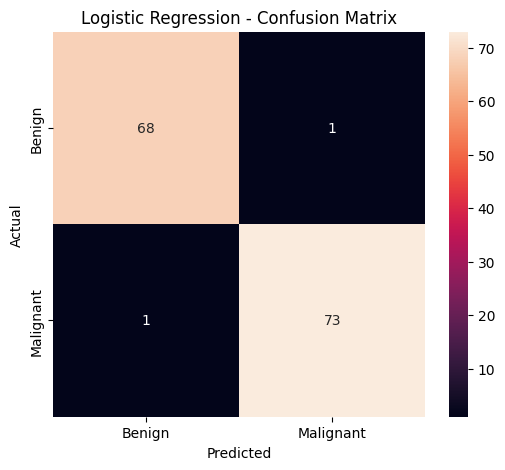

In [ ]:

# 18. Confusion Matrix

cm = confusion_matrix(
    y_test,
    y_pred_lr
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=['Benign', 'Malignant'],
    yticklabels=['Benign', 'Malignant']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression - Confusion Matrix")

plt.show()

## Random Forest with Balanced Data

In [ ]:
# 19. Random Forest (using pre-scaled and pre-balanced data)

# X_train_balanced, y_train_balanced, X_test_scaled, y_test are prepared
# in the "Split, Scale, and Balance Training Data" section (e.g., cell Njdo3bQqEis1).

rf = RandomForestClassifier(
    n_estimators=300,
    random_state=42
)

rf.fit(
    X_train_balanced,  # Use already balanced and scaled training data
    y_train_balanced
)

y_pred_rf = rf.predict(X_test_scaled) # Use already scaled test data
y_prob_rf = rf.predict_proba(X_test_scaled)[:, 1] # Use already scaled test data

In [ ]:
print("Accuracy:",
      accuracy_score(y_test, y_pred_rf))

print("Precision:",
      precision_score(y_test, y_pred_rf, pos_label='M'))

print("Recall:",
      recall_score(y_test, y_pred_rf, pos_label='M'))

print("F1 Score:",
      f1_score(y_test, y_pred_rf, pos_label='M'))

print("ROC-AUC:",
      roc_auc_score(y_test, y_prob_rf))

Accuracy: 0.972027972027972
Precision: 0.9605263157894737
Recall: 0.9864864864864865
F1 Score: 0.9733333333333334
ROC-AUC: 0.9962788875832355


## XGBoost with Balanced Data

In [ ]:
# 20. XGBoost (using pre-scaled and pre-balanced data)

# X_train_balanced, y_train_balanced, X_test_scaled, y_test are prepared
# in the "Split, Scale, and Balance Training Data" section (e.g., cell Njdo3bQqEis1).

# XGBoost requires numerical labels for binary classification (0 and 1).
# Map 'B' (Benign) to 0 and 'M' (Malignant) to 1 for training.
# This mapping needs to be applied to the already balanced y_train_balanced.
y_train_balanced_encoded = y_train_balanced.map({'B': 0, 'M': 1})

xgb = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.9,
    colsample_bytree=0.9,
    objective='binary:logistic',
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)

xgb.fit(
    X_train_balanced,  # Use already balanced and scaled training data
    y_train_balanced_encoded # Use the encoded numerical labels for fitting
)

# Make predictions. The output (y_pred_xgb_numerical) will be numerical (0 or 1).
y_pred_xgb_numerical = xgb.predict(X_test_scaled) # Use already scaled test data

# Convert numerical predictions back to original string labels ('B', 'M')
# for consistency with y_test in evaluation metrics.
y_pred_xgb = pd.Series(y_pred_xgb_numerical).map({0: 'B', 1: 'M'})

# Get probabilities for the positive class (1, which corresponds to 'M').
y_prob_xgb = xgb.predict_proba(X_test_scaled)[:, 1] # Use already scaled test data

In [ ]:
# Evaluate XGBoost
print("Accuracy:",
      accuracy_score(y_test, y_pred_xgb))

print("Precision:",
      precision_score(y_test, y_pred_xgb, pos_label='M'))

print("Recall:",
      recall_score(y_test, y_pred_xgb, pos_label='M'))

print("F1 Score:",
      f1_score(y_test, y_pred_xgb, pos_label='M'))

print("ROC-AUC:",
      roc_auc_score(y_test, y_prob_xgb))

Accuracy: 0.965034965034965
Precision: 0.948051948051948
Recall: 0.9864864864864865
F1 Score: 0.9668874172185431
ROC-AUC: 0.9992166079122601


In [ ]:
print(
    classification_report(
        y_test,
        y_pred_xgb,
        target_names=['Benign', 'Malignant']
    )
)

              precision    recall  f1-score   support

      Benign       0.98      0.94      0.96        69
   Malignant       0.95      0.99      0.97        74

    accuracy                           0.97       143
   macro avg       0.97      0.96      0.96       143
weighted avg       0.97      0.97      0.96       143



## Compare All Models

In [ ]:

# 21. Model Comparison After SMOTE

results = pd.DataFrame({

    'Model': [
        'Logistic Regression',
        'Random Forest',
        'XGBoost'
    ],

    'Accuracy': [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_xgb)
    ],

    'Precision': [
        precision_score(y_test, y_pred_lr, pos_label='M'),
        precision_score(y_test, y_pred_rf, pos_label='M'),
        precision_score(y_test, y_pred_xgb, pos_label='M')
    ],

    'Recall': [
        recall_score(y_test, y_pred_lr, pos_label='M'),
        recall_score(y_test, y_pred_rf, pos_label='M'),
        recall_score(y_test, y_pred_xgb, pos_label='M')
    ],

    'F1 Score': [
        f1_score(y_test, y_pred_lr, pos_label='M'),
        f1_score(y_test, y_pred_rf, pos_label='M'),
        f1_score(y_test, y_pred_xgb, pos_label='M')
    ],

    'ROC-AUC': [
        roc_auc_score(y_test, y_prob_lr),
        roc_auc_score(y_test, y_prob_rf),
        roc_auc_score(y_test, y_prob_xgb)
    ]
})

print(results)


                 Model  Accuracy  Precision    Recall  F1 Score   ROC-AUC
0  Logistic Regression  0.986014   0.986486  0.986486  0.986486  0.999412
1        Random Forest  0.972028   0.960526  0.986486  0.973333  0.996279
2              XGBoost  0.965035   0.948052  0.986486  0.966887  0.999217


In [ ]:
# Feature Importance After Balancing
importance = pd.Series(
    xgb.feature_importances_,
    index=X.columns
)

importance = importance.sort_values(
    ascending=False
)

print(importance.head(10))

perimeter_worst         0.355029
concave points_mean     0.126291
radius_worst            0.118395
concave points_worst    0.104480
area_worst              0.041603
area_mean               0.034855
texture_se              0.017335
texture_worst           0.015613
symmetry_se             0.014774
concavity_worst         0.013633
dtype: float32


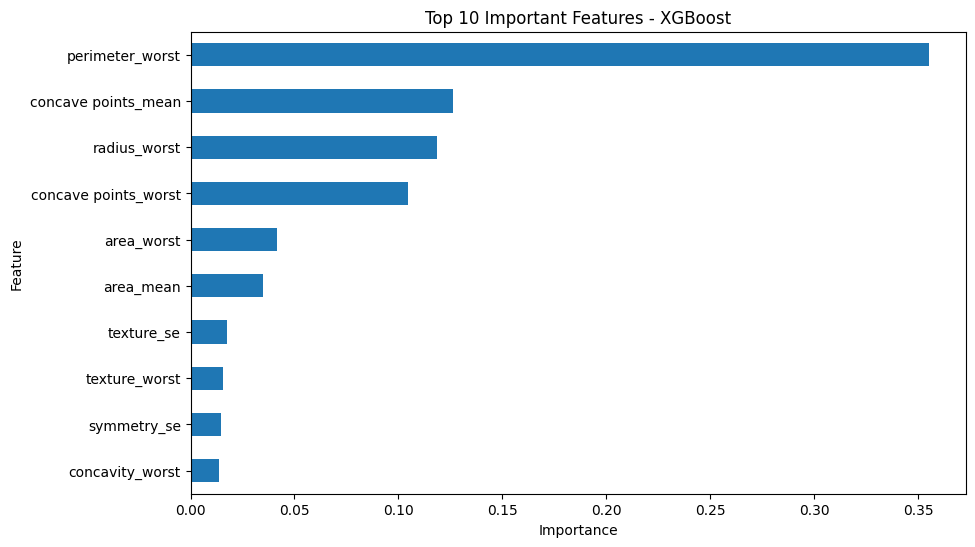

In [ ]:
plt.figure(figsize=(10, 6))

importance.head(10).sort_values().plot(
    kind='barh'
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 10 Important Features - XGBoost")

plt.show()

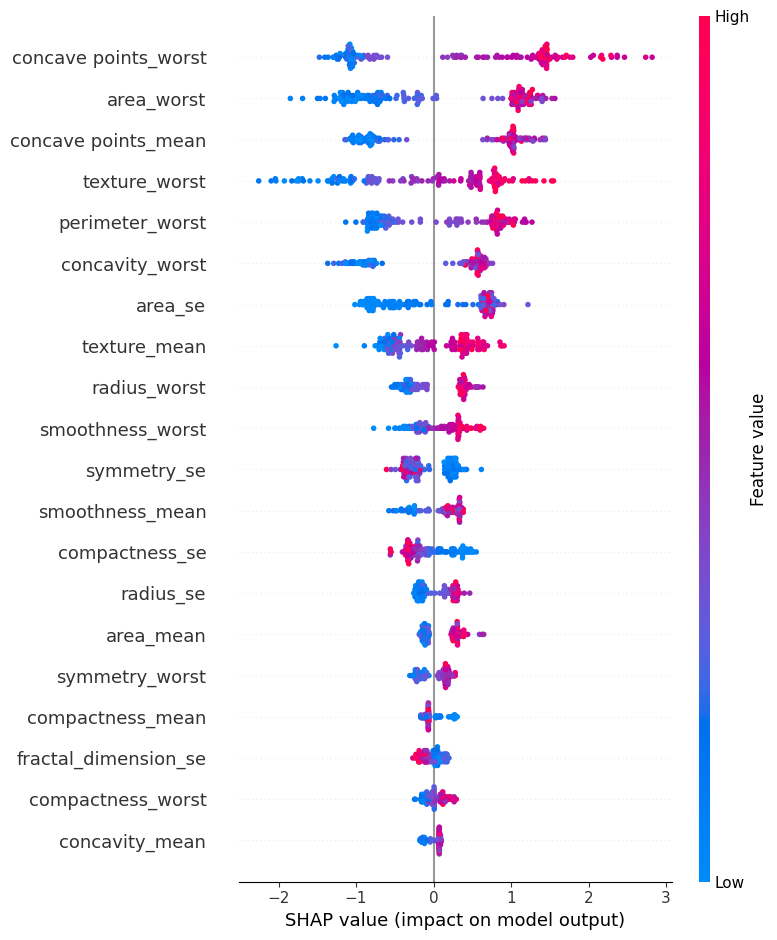

In [ ]:
# 23. SHAP Explainability

import shap

explainer = shap.TreeExplainer(xgb)

shap_values = explainer.shap_values(X_test)

shap.summary_plot(
    shap_values,
    X_test,
    feature_names=X.columns
)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 9.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283913 sha256=7383f33701786705b6610578bffc9492cb36d47d98711de8be59e5f761e3f2be
  Stored in directory: /root/.cache/pip/wheels/7c/04/5c/157dc9106512a6c7a30653ec064490c94a49e0fc8f63d19ab9
Successfully built lime


[('texture_worst <= 22.10', -0.2455788088004768), ('area_worst <= 544.15', -0.21180665189688172), ('0.07 < concave points_worst <= 0.12', -0.15636464411806258), ('area_se <= 19.17', -0.14383186209869173), ('perimeter_worst <= 86.61', -0.13704265154331596), ('texture_mean <= 16.97', -0.12446888759509432), ('radius_worst <= 13.32', -0.09324673962319463), ('0.02 < concave points_mean <= 0.05', -0.07728724938580474), ('symmetry_se <= 0.02', 0.07088512824127767), ('smoothness_worst > 0.15', 0.050590786792134176)]


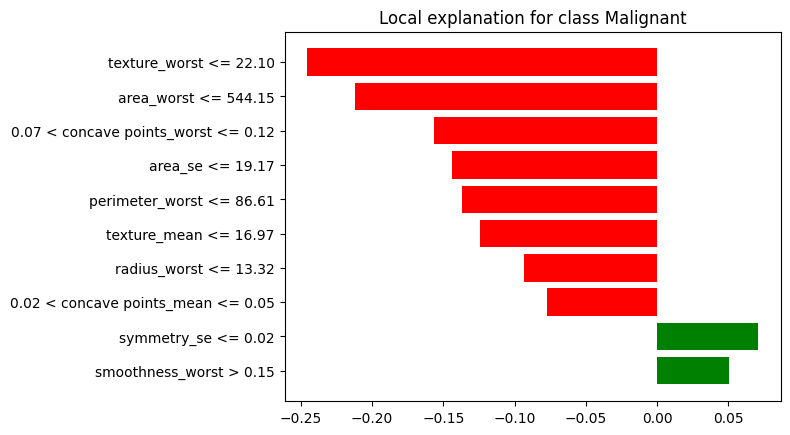

In [ ]:
# ===== LIME Explainability (per-patient explanation) =====

# Install if needed: !pip install lime
!pip install lime
from lime.lime_tabular import LimeTabularExplainer

# 1. Build the explainer using the TRAINING data distribution
explainer_lime = LimeTabularExplainer(
    training_data=X_train.values,          # numpy array of training features
    feature_names=X.columns.tolist(),
    class_names=['Benign', 'Malignant'],
    mode='classification'
)
# Why: LIME needs to know the realistic range/distribution of each feature
# so it can generate plausible perturbed samples around the point being explained.

# 2. Pick one patient from the test set to explain (e.g. the first one)
i = 0
sample = X_test.iloc[i].values

# 3. Generate the explanation
# xgb.predict_proba expects the same feature format the model was trained on
exp = explainer_lime.explain_instance(
    data_row=sample,
    predict_fn=xgb.predict_proba,
    num_features=10                        # show top 10 contributing features
)

# 4. Show results
exp.show_in_notebook(show_table=True)      # interactive view (Jupyter/Colab)
print(exp.as_list())                       # plain list: (feature condition, weight)

# 5. Optional: explain a few patients and save as a static plot for your slides
fig = exp.as_pyplot_figure()
fig.savefig("lime_explanation_patient0.png", bbox_inches='tight')